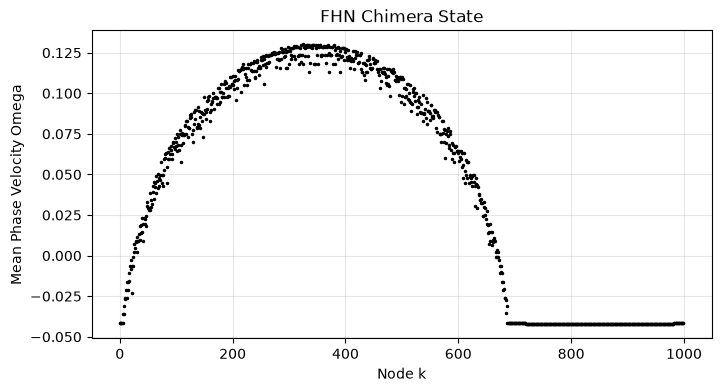

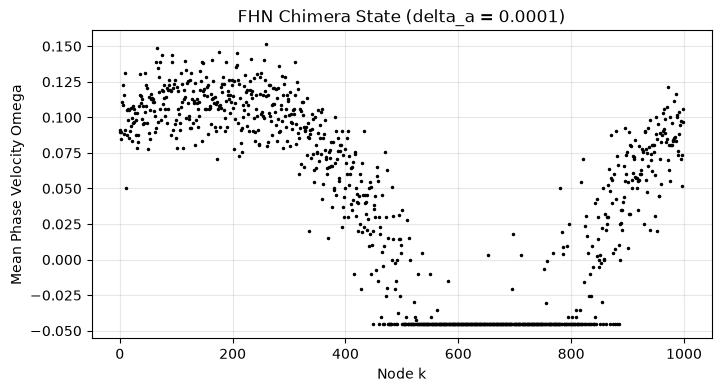

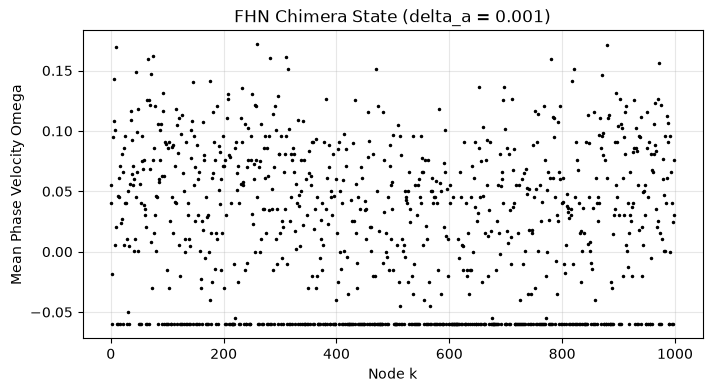

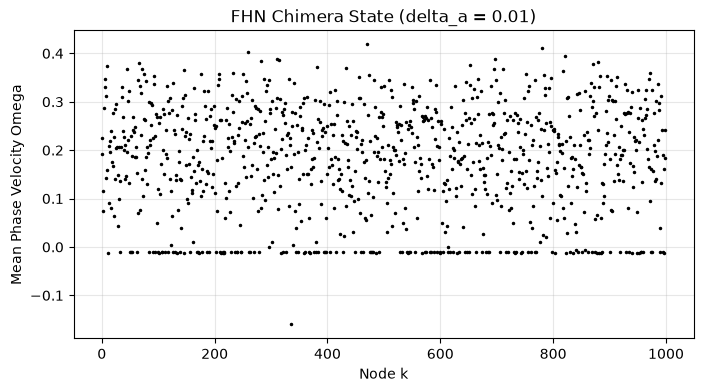

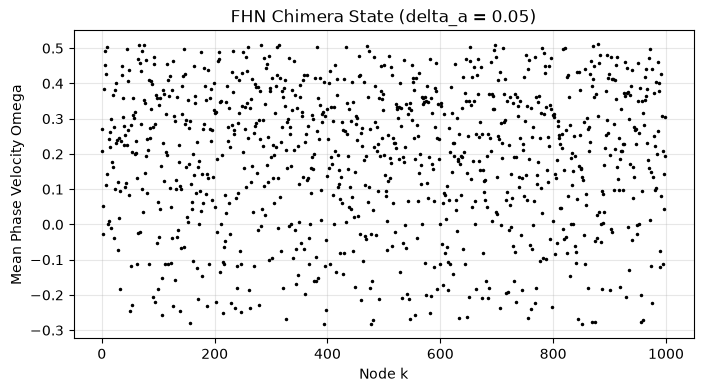

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.ndimage import convolve1d

# Parameters
N = 1000
epsilon = 0.05
r = 0.35 #coupling radius 
sigma = 0.1 #coupling strength
phi = np.pi/2 - 0.1 #coupling phase

#Rotational matrix
buu = np.cos(phi)
buv = np.sin(phi)
bvu = -np.sin(phi)
bvv = np.cos(phi)

R = int(N * r) #350 neighbors on each side
#kernel with 1s for neighboring nodes
kernel = np.ones(2 * R + 1)
kernel[R] = 0.0

T_max = 2500 
t_span = (0, T_max)
t_eval = np.linspace(0, T_max, 500) 

variances = [0, 0.0001, 0.001, 0.01, 0.05] 

for delta_a in variances:
    if delta_a == 0:
        ak = 0.5
    else:
        # variance
        # threshhold parameter with different values
        ak = np.random.normal(loc=0.5, scale=np.sqrt(delta_a), size=N) 
        
    # initial conds
    #u^2 + v^2 = 4
    np.random.seed(42) #seed for reproducibility
    theta_init = np.random.uniform(0, 2*np.pi, N)
    u0 = 2 * np.cos(theta_init)
    v0 = 2 * np.sin(theta_init)
    y0 = np.concatenate([u0, v0])

    def fhn_deriv(t, y):
        u = y[:N]
        v = y[N:]
        sum_uj = convolve1d(u, kernel, mode='wrap')
        sum_vj = convolve1d(v, kernel, mode='wrap')
        diff_u = sum_uj - (2*R) * u
        diff_v = sum_vj - (2*R) * v

        coupling_u = buu * diff_u + buv * diff_v
        coupling_v = bvu * diff_u + bvv * diff_v

        du_dt = (1.0/epsilon) * (u - (u**3)/3.0 - v + (sigma / (2*R)) * coupling_u)
        dv_dt = u + ak + (sigma / (2*R)) * coupling_v

        return np.concatenate([du_dt, dv_dt])

    sol = solve_ivp(fhn_deriv, t_span, y0, method='RK45', t_eval=t_eval)

    # Re-separate u and v from the solution
    u_sol = sol.y[:N, 250:]
    v_sol = sol.y[N:, 250:]

    # To calculate phase velocity, we get the phase angle (arctan2) and unwrap it so it doesn't jump at 2*pi
    phases = np.unwrap(np.arctan2(v_sol, u_sol), axis=1)

    # Mean phase velocity = total phase change / total time
    time_window = t_eval[-1] - t_eval[250]
    omega = (phases[:, -1] - phases[:, 0]) / time_window

    omega = np.roll(omega, 500)

    plt.figure(figsize=(8, 4))
    plt.plot(omega, 'k.', markersize=3)
    plt.xlabel('Node k')
    plt.ylabel('Mean Phase Velocity Omega')
    
    if delta_a == 0:
        plt.title('FHN Chimera State')
    else:
        plt.title(f'FHN Chimera State (delta_a = {delta_a})')
        
    plt.grid(True, alpha=0.3)
    plt.show()

# The Effect of Inhomogeneity 